In [1]:
import pandas as pd

df = pd.read_csv("recruitmentdataset-2022-1.3.csv")
print(df.shape)
print(df.columns.tolist())

(4000, 15)
['Id', 'gender', 'age', 'nationality', 'sport', 'ind-university_grade', 'ind-debateclub', 'ind-programming_exp', 'ind-international_exp', 'ind-entrepeneur_exp', 'ind-languages', 'ind-exact_study', 'ind-degree', 'company', 'decision']


In [1]:
b = df[df['company'] == 'B']
ind_cols = [c for c in df.columns if c.startswith('ind-')]
print(b[ind_cols].dtypes)
print(b[ind_cols].head())

NameError: name 'df' is not defined

In [1]:
import pandas as pd

df = pd.read_csv("recruitmentdataset-2022-1.3.csv")
nitelikler = [c for c in df.columns if c.startswith("ind-")]

b = df[(df["company"] == "B") & (df["gender"].isin(["male", "female"]))]

# nitelikleri birebir aynı olan gruplar içinde, hem kadın hem erkek bulunanları tut
eslesen = b.groupby(nitelikler).filter(lambda g: g["gender"].nunique() == 2)

print("Eşleşen aday sayısı:", len(eslesen))
print(eslesen.groupby("gender")["decision"].mean())

Eşleşen aday sayısı: 431
gender
female    0.127193
male      0.256158
Name: decision, dtype: float64


In [2]:
print(df['decision'].value_counts())
print(df['gender'].value_counts())
print(df['nationality'].value_counts())
print(df['company'].value_counts())
print(df.isnull().sum())

decision
False    2733
True     1267
Name: count, dtype: int64
gender
male      2127
female    1790
other       83
Name: count, dtype: int64
nationality
Dutch      3167
Belgian     434
German      399
Name: count, dtype: int64
company
A    1000
B    1000
C    1000
D    1000
Name: count, dtype: int64
Id                       0
gender                   0
age                      0
nationality              0
sport                    0
ind-university_grade     0
ind-debateclub           0
ind-programming_exp      0
ind-international_exp    0
ind-entrepeneur_exp      0
ind-languages            0
ind-exact_study          0
ind-degree               0
company                  0
decision                 0
dtype: int64


In [3]:
print(df.groupby('company')['decision'].mean())
print(df.groupby('gender')['decision'].mean())
print(df.groupby('nationality')['decision'].mean())
print(df.groupby(['company','gender'])['decision'].mean())

company
A    0.424
B    0.309
C    0.258
D    0.276
Name: decision, dtype: float64
gender
female    0.274860
male      0.352609
other     0.301205
Name: decision, dtype: float64
nationality
Belgian    0.308756
Dutch      0.318598
German     0.310777
Name: decision, dtype: float64
company  gender
A        female    0.386005
         male      0.456562
         other     0.375000
B        female    0.139690
         male      0.454717
         other     0.263158
C        female    0.233996
         male      0.276718
         other     0.304348
D        female    0.343115
         male      0.219925
         other     0.280000
Name: decision, dtype: float64


In [4]:
pd.set_option('display.max_rows', None)
print(df.groupby(['company','gender'])['decision'].mean())
print(df.groupby(['company','gender']).size())


company  gender
A        female    0.386005
         male      0.456562
         other     0.375000
B        female    0.139690
         male      0.454717
         other     0.263158
C        female    0.233996
         male      0.276718
         other     0.304348
D        female    0.343115
         male      0.219925
         other     0.280000
Name: decision, dtype: float64
company  gender
A        female    443
         male      541
         other      16
B        female    451
         male      530
         other      19
C        female    453
         male      524
         other      23
D        female    443
         male      532
         other      25
dtype: int64


In [5]:
sonuc = df[df['gender'].isin(['female','male'])].groupby(['company','gender'])['decision'].mean().unstack()
sonuc['disparate_impact_orani'] = sonuc[['female','male']].min(axis=1) / sonuc[['female','male']].max(axis=1)
print(sonuc)

gender     female      male  disparate_impact_orani
company                                            
A        0.386005  0.456562                0.845459
B        0.139690  0.454717                0.307201
C        0.233996  0.276718                0.845612
D        0.343115  0.219925                0.640965


In [2]:
def grup_orani(g):
    f = g[g["gender"] == "female"]["decision"]
    m = g[g["gender"] == "male"]["decision"]
    w = min(len(f), len(m))
    return pd.Series({"kadin": f.mean(), "erkek": m.mean(), "agirlik": w})

sonuc = eslesen.groupby(nitelikler).apply(grup_orani)

kadin = (sonuc["kadin"] * sonuc["agirlik"]).sum() / sonuc["agirlik"].sum()
erkek = (sonuc["erkek"] * sonuc["agirlik"]).sum() / sonuc["agirlik"].sum()
print("Kadın:", kadin, "Erkek:", erkek, "Oran:", kadin / erkek)

Kadın: 0.18850574712643678 Erkek: 0.22873563218390802 Oran: 0.8241206030150755


In [3]:
import numpy as np

def oran_hesapla(d):
    e = d.groupby(nitelikler).filter(lambda g: g["gender"].nunique() == 2)
    if len(e) == 0:
        return np.nan, np.nan, np.nan, 0
    s = e.groupby(nitelikler).apply(grup_orani)
    w = s["agirlik"].sum()
    k = (s["kadin"] * s["agirlik"]).sum() / w
    m = (s["erkek"] * s["agirlik"]).sum() / w
    return k, m, k / m, w

for sirket in ["A", "B", "C", "D"]:
    d = df[(df["company"] == sirket) & (df["gender"].isin(["male", "female"]))]
    k, m, oran, w = oran_hesapla(d)
    oranlar = [oran_hesapla(d.sample(len(d), replace=True))[2] for _ in range(200)]
    alt, ust = np.nanpercentile(oranlar, [2.5, 97.5])
    print(f"{sirket}: kadın={k:.3f} erkek={m:.3f} oran={oran:.3f} "
          f"%95 aralık=({alt:.2f}, {ust:.2f}) etkin ağırlık={w}")

A: kadın=0.411 erkek=0.369 oran=1.112 %95 aralık=(0.90, 1.41) etkin ağırlık=181.0
B: kadın=0.189 erkek=0.229 oran=0.824 %95 aralık=(0.61, 1.12) etkin ağırlık=145.0
C: kadın=0.181 erkek=0.191 oran=0.946 %95 aralık=(0.62, 1.40) etkin ağırlık=159.0
D: kadın=0.326 erkek=0.296 oran=1.102 %95 aralık=(0.95, 1.30) etkin ağırlık=168.0


In [4]:
import statsmodels.api as sm

for sirket in ["A", "B", "C", "D"]:
    d = df[(df["company"] == sirket) & (df["gender"].isin(["male", "female"]))].copy()
    X = pd.get_dummies(d[nitelikler + ["age"]], drop_first=True).astype(float)
    X["kadin"] = (d["gender"] == "female").astype(float)
    X = sm.add_constant(X)
    y = d["decision"].astype(int)
    m = sm.Logit(y, X).fit(disp=0)
    oran = np.exp(m.params["kadin"])
    alt, ust = np.exp(m.conf_int().loc["kadin"])
    print(f"{sirket}: kadın odds oranı={oran:.2f}  %95 aralık=({alt:.2f}, {ust:.2f})  p={m.pvalues['kadin']:.3f}")

ModuleNotFoundError: No module named 'statsmodels'

In [5]:
%pip install statsmodels

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.6/11.6 MB 51.9 MB/s  0:00:00eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [statsmodels] [statsmodels]

[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv("recruitmentdataset-2022-1.3.csv")
nitelikler = [c for c in df.columns if c.startswith("ind-")]
print(len(df), nitelikler)

4000 ['ind-university_grade', 'ind-debateclub', 'ind-programming_exp', 'ind-international_exp', 'ind-entrepeneur_exp', 'ind-languages', 'ind-exact_study', 'ind-degree']


In [2]:
import statsmodels.api as sm

for sirket in ["A", "B", "C", "D"]:
    d = df[(df["company"] == sirket) & (df["gender"].isin(["male", "female"]))].copy()
    X = pd.get_dummies(d[nitelikler + ["age"]], drop_first=True).astype(float)
    X["kadin"] = (d["gender"] == "female").astype(float)
    X = sm.add_constant(X)
    y = d["decision"].astype(int)
    m = sm.Logit(y, X).fit(disp=0)
    oran = np.exp(m.params["kadin"])
    alt, ust = np.exp(m.conf_int().loc["kadin"])
    print(f"{sirket}: kadın odds oranı={oran:.2f}  %95 aralık=({alt:.2f}, {ust:.2f})  p={m.pvalues['kadin']:.3f}")

A: kadın odds oranı=1.18  %95 aralık=(0.84, 1.65)  p=0.342
B: kadın odds oranı=0.49  %95 aralık=(0.30, 0.82)  p=0.006
C: kadın odds oranı=1.26  %95 aralık=(0.84, 1.90)  p=0.266
D: kadın odds oranı=1.22  %95 aralık=(0.75, 2.00)  p=0.419


In [3]:
def kadin_etkisi(sirket, ekstra=[]):
    d = df[(df["company"] == sirket) & (df["gender"].isin(["male", "female"]))].copy()
    X = pd.get_dummies(d[nitelikler + ["age"] + ekstra], drop_first=True).astype(float)
    X["kadin"] = (d["gender"] == "female").astype(float)
    X = sm.add_constant(X)
    y = d["decision"].astype(int)
    m = sm.Logit(y, X).fit(disp=0)
    oran = np.exp(m.params["kadin"])
    alt, ust = np.exp(m.conf_int().loc["kadin"])
    return m, oran, alt, ust, m.pvalues["kadin"]

for ekstra in [[], ["nationality"], ["nationality", "sport"]]:
    m, oran, alt, ust, p = kadin_etkisi("B", ekstra)
    print(f"ekstra={ekstra}: OR={oran:.2f} ({alt:.2f}, {ust:.2f}) p={p:.3f}")

ekstra=[]: OR=0.49 (0.30, 0.82) p=0.006
ekstra=['nationality']: OR=0.49 (0.29, 0.81) p=0.006
ekstra=['nationality', 'sport']: OR=0.57 (0.33, 0.99) p=0.044


In [4]:
b = df[(df["company"] == "B") & (df["gender"].isin(["male", "female"]))]

print(pd.crosstab(b["sport"], b["gender"], normalize="columns").round(2))
print(b.groupby("sport")["decision"].agg(["mean", "size"]).round(2))

gender    female  male
sport                 
Chess       0.18  0.02
Cricket     0.08  0.08
Football    0.15  0.29
Golf        0.08  0.09
Rugby       0.08  0.27
Running     0.13  0.04
Swimming    0.23  0.10
Tennis      0.08  0.12
          mean  size
sport               
Chess     0.02    91
Cricket   0.18    79
Football  0.46   223
Golf      0.05    82
Rugby     0.54   176
Running   0.07    76
Swimming  0.20   157
Tennis    0.52    97


In [5]:
tablo = pd.pivot_table(df, index="sport", columns="company",
                       values="decision", aggfunc="mean").round(2)
print(tablo)

company      A     B     C     D
sport                           
Chess     0.37  0.02  0.24  0.41
Cricket   0.34  0.18  0.38  0.31
Football  0.46  0.46  0.25  0.22
Golf      0.41  0.05  0.33  0.33
Rugby     0.55  0.54  0.40  0.14
Running   0.27  0.06  0.12  0.40
Swimming  0.42  0.21  0.21  0.33
Tennis    0.40  0.50  0.13  0.24


In [6]:
mf = df[df["gender"].isin(["male", "female"])]
dagilim = pd.crosstab(mf["sport"], mf["gender"], normalize="columns")

tablo = pd.pivot_table(df, index="sport", columns="company",
                       values="decision", aggfunc="mean")

for s in ["A", "B", "C", "D"]:
    k = (dagilim["female"] * tablo[s]).sum()
    e = (dagilim["male"] * tablo[s]).sum()
    print(f"{s}: kadın={k:.3f} erkek={e:.3f}  spor-kaynaklı oran={min(k, e) / max(k, e):.3f}")

A: kadın=0.398 erkek=0.447  spor-kaynaklı oran=0.890
B: kadın=0.231 erkek=0.374  spor-kaynaklı oran=0.618
C: kadın=0.238 erkek=0.283  spor-kaynaklı oran=0.841
D: kadın=0.315 erkek=0.243  spor-kaynaklı oran=0.772


In [7]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

def baslangic(sirket, ozellikler):
    d = df[(df["company"] == sirket) & (df["gender"].isin(["male", "female"]))].copy()
    X = pd.get_dummies(d[ozellikler], drop_first=True).astype(float)
    y = d["decision"].astype(int)
    g = d["gender"]
    X_tr, X_te, y_tr, y_te, g_tr, g_te = train_test_split(
        X, y, g, test_size=0.3, random_state=42, stratify=y)
    model = LogisticRegression(max_iter=1000).fit(X_tr, y_tr)
    tahmin = pd.Series(model.predict(X_te), index=g_te.index)
    oranlar = tahmin.groupby(g_te).mean()
    di = min(oranlar) / max(oranlar)
    print(f"doğruluk={accuracy_score(y_te, tahmin):.3f}  "
          f"kadın seçilme={oranlar['female']:.3f}  erkek={oranlar['male']:.3f}  "
          f"oran={di:.3f}")

temel = nitelikler + ["age", "nationality"]
print("sport DAHİL:")
baslangic("B", temel + ["sport"])
print("sport HARİÇ:")
baslangic("B", temel)

sport DAHİL:
doğruluk=0.888  kadın seçilme=0.128  erkek=0.401  oran=0.319
sport HARİÇ:
doğruluk=0.888  kadın seçilme=0.143  erkek=0.377  oran=0.379


In [2]:
import pandas as pd

df = pd.read_csv("recruitmentdataset-2022-1.3.csv")

b = df[df['company'] == 'B']
ind_cols = [c for c in df.columns if c.startswith('ind-')]
print(b[ind_cols].dtypes)
print(b[ind_cols].head())

ind-university_grade     int64
ind-debateclub            bool
ind-programming_exp       bool
ind-international_exp     bool
ind-entrepeneur_exp       bool
ind-languages            int64
ind-exact_study           bool
ind-degree                 str
dtype: object
      ind-university_grade  ind-debateclub  ind-programming_exp  \
1000                    58           False                False   
1001                    67           False                False   
1002                    56            True                False   
1003                    64           False                False   
1004                    63            True                False   

      ind-international_exp  ind-entrepeneur_exp  ind-languages  \
1000                  False                False              0   
1001                   True                False              0   
1002                  False                False              2   
1003                   True                False              0   


In [3]:
from sklearn.model_selection import train_test_split

X = pd.get_dummies(b[ind_cols], columns=['ind-degree'], drop_first=True)
y = b['decision']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

print(X.columns.tolist())
print(X_train.shape, X_test.shape)
print(y_train.mean(), y_test.mean())

['ind-university_grade', 'ind-debateclub', 'ind-programming_exp', 'ind-international_exp', 'ind-entrepeneur_exp', 'ind-languages', 'ind-exact_study', 'ind-degree_master', 'ind-degree_phd']
(700, 9) (300, 9)
0.30857142857142855 0.31


In [4]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

pred = model.predict(X_test)

print("Model doğruluğu:", accuracy_score(y_test, pred))
print("Hepsine 'alma' deseydik doğruluk:", 1 - y_test.mean())

Model doğruluğu: 0.8766666666666667
Hepsine 'alma' deseydik doğruluk: 0.69


In [5]:
test_gender = b.loc[X_test.index, 'gender']

res = pd.DataFrame({'gender': test_gender, 'model_karari': pred, 'gercek_karar': y_test})

print(res.groupby('gender')['model_karari'].agg(['mean', 'count']))
print(res.groupby('gender')['gercek_karar'].mean())

oranlar = res[res['gender'].isin(['female', 'male'])].groupby('gender')['model_karari'].mean()
print("Modelin disparate impact oranı:", oranlar.min() / oranlar.max())

            mean  count
gender                 
female  0.136364    132
male    0.462963    162
other   0.500000      6
gender
female    0.159091
male      0.438272
other     0.166667
Name: gercek_karar, dtype: float64
Modelin disparate impact oranı: 0.2945454545454545


In [6]:
egitim = pd.read_csv("data.csv", sep=";")
print(egitim.shape)
print(egitim.columns.tolist())

(4424, 37)
['Marital status', 'Application mode', 'Application order', 'Course', 'Daytime/evening attendance\t', 'Previous qualification', 'Previous qualification (grade)', 'Nacionality', "Mother's qualification", "Father's qualification", "Mother's occupation", "Father's occupation", 'Admission grade', 'Displaced', 'Educational special needs', 'Debtor', 'Tuition fees up to date', 'Gender', 'Scholarship holder', 'Age at enrollment', 'International', 'Curricular units 1st sem (credited)', 'Curricular units 1st sem (enrolled)', 'Curricular units 1st sem (evaluations)', 'Curricular units 1st sem (approved)', 'Curricular units 1st sem (grade)', 'Curricular units 1st sem (without evaluations)', 'Curricular units 2nd sem (credited)', 'Curricular units 2nd sem (enrolled)', 'Curricular units 2nd sem (evaluations)', 'Curricular units 2nd sem (approved)', 'Curricular units 2nd sem (grade)', 'Curricular units 2nd sem (without evaluations)', 'Unemployment rate', 'Inflation rate', 'GDP', 'Target']


In [7]:
print(egitim['Target'].value_counts())
print(egitim['Gender'].value_counts())
print(pd.crosstab(egitim['Gender'], egitim['Target'], normalize='index').round(3))

Target
Graduate    2209
Dropout     1421
Enrolled     794
Name: count, dtype: int64
Gender
0    2868
1    1556
Name: count, dtype: int64
Target  Dropout  Enrolled  Graduate
Gender                             
0         0.251     0.170     0.579
1         0.451     0.197     0.352


In [8]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

X = egitim.drop(columns=['Target', 'Gender'])
y = egitim['Target']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

model = RandomForestClassifier(random_state=42)
model.fit(X_train, y_train)

print("Doğruluk:", accuracy_score(y_test, model.predict(X_test)))


Doğruluk: 0.7838855421686747


In [9]:
res = pd.DataFrame({
    'gender': egitim.loc[X_test.index, 'Gender'],
    'gercek': y_test,
    'tahmin': model.predict(X_test)
})
res['dogru'] = res['gercek'] == res['tahmin']

print(res.groupby('gender')['dogru'].mean())
print(res.assign(gercek_dropout=res['gercek'] == 'Dropout',
                 tahmin_dropout=res['tahmin'] == 'Dropout')
         .groupby('gender')[['gercek_dropout', 'tahmin_dropout']].mean())

gender
0    0.804373
1    0.745098
Name: dogru, dtype: float64
        gercek_dropout  tahmin_dropout
gender                                
0             0.249712        0.235903
1             0.457516        0.431373


In [10]:
res['g_d'] = res['gercek'] == 'Dropout'
res['t_d'] = res['tahmin'] == 'Dropout'

for g, d in res.groupby('gender'):
    kacirilan = (d['g_d'] & ~d['t_d']).sum() / d['g_d'].sum()
    yanlis_alarm = (~d['g_d'] & d['t_d']).sum() / (~d['g_d']).sum()
    print(f"Grup {g} | kaçırılan bırakma: {kacirilan:.3f} | yanlış alarm: {yanlis_alarm:.3f}")

Grup 0 | kaçırılan bırakma: 0.249 | yanlış alarm: 0.064
Grup 1 | kaçırılan bırakma: 0.224 | yanlış alarm: 0.141


In [11]:
Xg = egitim.drop(columns=['Target'])
Xg_train, Xg_test, yg_train, yg_test = train_test_split(Xg, y, test_size=0.3, random_state=42, stratify=y)

model_g = RandomForestClassifier(random_state=42).fit(Xg_train, yg_train)

Xg_flip = Xg_test.copy()
Xg_flip['Gender'] = 1 - Xg_flip['Gender']

i = list(model_g.classes_).index('Dropout')
p = model_g.predict_proba(Xg_test)[:, i]
p_flip = model_g.predict_proba(Xg_flip)[:, i]

print("Ortalama bırakma riski değişimi:", (p_flip - p).mean())
print("Tahmini değişen öğrenci oranı:", (model_g.predict(Xg_test) != model_g.predict(Xg_flip)).mean())
print(pd.Series(p_flip - p).groupby(Xg_test['Gender'].values).mean())

Ortalama bırakma riski değişimi: 0.004367469879518072
Tahmini değişen öğrenci oranı: 0.03614457831325301
0    0.011312
1   -0.008780
dtype: float64


In [12]:
tab = egitim.groupby(['Course', 'Gender'])['Target'].agg(
    n='size', dropout=lambda s: (s == 'Dropout').mean()
).unstack()
print(tab.round(2))

          n      dropout      
Gender    0    1       0     1
Course                        
33        3    9    0.33  0.78
171      98  117    0.37  0.39
8014    173   42    0.31  0.40
9003     61  149    0.28  0.46
9070    130   96    0.17  0.30
9085    277   60    0.21  0.52
9119      7  163    0.86  0.53
9130     79   62    0.48  0.65
9147    218  162    0.25  0.49
9238    309   46    0.14  0.48
9254    152  100    0.34  0.44
9500    617  149    0.13  0.25
9556     67   19    0.31  0.63
9670    146  122    0.28  0.44
9773    216  115    0.28  0.36
9853    183    9    0.44  0.44
9991    132  136    0.41  0.60


In [13]:
print(egitim.groupby('Gender')[
    ['Debtor', 'Tuition fees up to date', 'Scholarship holder', 'Admission grade', 'Age at enrollment']
].mean().round(2))

        Debtor  Tuition fees up to date  Scholarship holder  Admission grade  \
Gender                                                                         
0         0.10                     0.91                0.30           126.89   
1         0.14                     0.83                0.15           127.14   

        Age at enrollment  
Gender                     
0                   22.43  
1                   24.80  


In [14]:
from sklearn.linear_model import LogisticRegression

b2 = df[(df['company'] == 'B') & (df['gender'].isin(['female', 'male']))].copy()
h_X = pd.get_dummies(b2[ind_cols], columns=['ind-degree'], drop_first=True)
h_X['male'] = (b2['gender'] == 'male').astype(int)
h_y = b2['decision']

h_Xtr, h_Xte, h_ytr, h_yte = train_test_split(h_X, h_y, test_size=0.3, random_state=42, stratify=h_y)
h_model = LogisticRegression(max_iter=1000).fit(h_Xtr, h_ytr)

h_flip = h_Xte.copy()
h_flip['male'] = 1 - h_flip['male']

p = h_model.predict_proba(h_Xte)[:, 1]
p_flip = h_model.predict_proba(h_flip)[:, 1]

print("Ortalama kabul olasılığı değişimi:", (p_flip - p).mean())
print(pd.Series(p_flip - p).groupby(h_Xte['male'].values).mean())

Ortalama kabul olasılığı değişimi: -0.018818230925508276
0    0.036650
1   -0.064357
dtype: float64


In [15]:
h_model2 = LogisticRegression(penalty=None, max_iter=5000).fit(h_Xtr, h_ytr)

p2 = h_model2.predict_proba(h_Xte)[:, 1]
p2_flip = h_model2.predict_proba(h_flip)[:, 1]

print(pd.Series(p2_flip - p2).groupby(h_Xte['male'].values).mean())

0    0.034904
1   -0.064785
dtype: float64


/Users/gulserguralp/Desktop/bitirme-fairness/venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


In [1]:
import fairlearn
print("fairlearn:", fairlearn.__version__)

import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from fairlearn.metrics import MetricFrame, selection_rate, demographic_parity_ratio

df = pd.read_csv("recruitmentdataset-2022-1.3.csv")
b = df[(df['company'] == 'B') & (df['gender'].isin(['female', 'male']))].copy()

ind_cols = [c for c in df.columns if c.startswith('ind-')]
X = pd.get_dummies(b[ind_cols], columns=['ind-degree'], drop_first=True)
y = b['decision']
A = b['gender']

X_train, X_test, y_train, y_test, A_train, A_test = train_test_split(
    X, y, A, test_size=0.3, random_state=42, stratify=y
)

model = LogisticRegression(max_iter=1000).fit(X_train, y_train)
pred = model.predict(X_test)

mf = MetricFrame(
    metrics={'accuracy': accuracy_score, 'selection_rate': selection_rate},
    y_true=y_test, y_pred=pred, sensitive_features=A_test
)
print(mf.by_group)
print("Genel doğruluk:", accuracy_score(y_test, pred))
print("DI:", demographic_parity_ratio(y_test, pred, sensitive_features=A_test))

fairlearn: 0.14.0
        accuracy  selection_rate
gender                          
female  0.917293        0.142857
male    0.839506        0.376543
Genel doğruluk: 0.8745762711864407
DI: 0.3793911007025761


In [2]:
import numpy as np
from fairlearn.postprocessing import ThresholdOptimizer
from fairlearn.metrics import equalized_odds_difference

print("Gerçek işe alım oranı (test):")
print(y_test.groupby(A_test).mean())

def ozet(ad, y_pred):
    y_pred = np.asarray(y_pred)
    sr = MetricFrame(metrics=selection_rate, y_true=y_test, y_pred=y_pred,
                     sensitive_features=A_test).by_group
    return {
        'yöntem': ad,
        'doğruluk': round(accuracy_score(y_test, y_pred), 3),
        'kadın_oran': round(sr['female'], 3),
        'erkek_oran': round(sr['male'], 3),
        'DI': round(demographic_parity_ratio(y_test, y_pred, sensitive_features=A_test), 3),
        'EO_farkı': round(equalized_odds_difference(y_test, y_pred, sensitive_features=A_test), 3),
    }

sonuc = [ozet('Düzeltme yok', pred)]
for kisit in ['demographic_parity', 'equalized_odds']:
    to = ThresholdOptimizer(estimator=model, constraints=kisit, objective='accuracy_score',
                            prefit=True, predict_method='predict_proba')
    to.fit(X_train, y_train, sensitive_features=A_train)
    p = to.predict(X_test, sensitive_features=A_test, random_state=42)
    sonuc.append(ozet(kisit, p))

print(pd.DataFrame(sonuc).to_string(index=False))

Gerçek işe alım oranı (test):
gender
female    0.150376
male      0.438272
Name: decision, dtype: float64
            yöntem  doğruluk  kadın_oran  erkek_oran    DI  EO_farkı
      Düzeltme yok     0.875       0.143       0.377 0.379     0.046
demographic_parity     0.807       0.218       0.191 0.878     0.492
    equalized_odds     0.851       0.188       0.296 0.634     0.180


In [3]:
import numpy as np

print("Test seti grup x etiket sayıları:")
print(pd.crosstab(A_test, y_test))

strat = A.astype(str) + "_" + y.astype(str)

def ozet2(y_true, y_pred, A_t):
    y_pred = np.asarray(y_pred)
    return {
        'doğruluk': accuracy_score(y_true, y_pred),
        'DI': demographic_parity_ratio(y_true, y_pred, sensitive_features=A_t),
        'EO_farkı': equalized_odds_difference(y_true, y_pred, sensitive_features=A_t),
    }

kayit = []
for seed in range(30):
    Xtr, Xte, ytr, yte, Atr, Ate = train_test_split(
        X, y, A, test_size=0.3, random_state=seed, stratify=strat
    )
    m = LogisticRegression(max_iter=1000).fit(Xtr, ytr)
    kayit.append({'yöntem': 'Düzeltme yok', **ozet2(yte, m.predict(Xte), Ate)})
    for kisit in ['demographic_parity', 'equalized_odds']:
        to = ThresholdOptimizer(estimator=m, constraints=kisit, objective='accuracy_score',
                                prefit=True, predict_method='predict_proba')
        to.fit(Xtr, ytr, sensitive_features=Atr)
        p = to.predict(Xte, sensitive_features=Ate, random_state=seed)
        kayit.append({'yöntem': kisit, **ozet2(yte, p, Ate)})

sonuc30 = pd.DataFrame(kayit)
print(sonuc30.groupby('yöntem').agg(['mean', 'std']).round(3))

Test seti grup x etiket sayıları:
decision  False  True 
gender                
female      113     20
male         91     71
                   doğruluk            DI        EO_farkı       
                       mean    std   mean    std     mean    std
yöntem                                                          
Düzeltme yok          0.874  0.018  0.332  0.055    0.160  0.084
demographic_parity    0.812  0.022  0.866  0.085    0.427  0.084
equalized_odds        0.854  0.018  0.493  0.084    0.094  0.058


In [4]:
from fairlearn.metrics import true_positive_rate, false_positive_rate

# 1) eşleştirilmiş fark
sonuc30['seed'] = np.repeat(range(30), 3)
pv = sonuc30.pivot(index='seed', columns='yöntem')
for yon in ['demographic_parity', 'equalized_odds']:
    fark = pv.xs(yon, axis=1, level=1) - pv.xs('Düzeltme yok', axis=1, level=1)
    print(f"\n{yon} - Düzeltme yok (30 bölme):")
    print(pd.DataFrame({'ort_fark': fark.mean(),
                        '±%95': 1.96 * fark.std() / np.sqrt(len(fark))}).round(3))

# 2) grup bazında TPR/FPR
satir = []
for seed in range(30):
    Xtr, Xte, ytr, yte, Atr, Ate = train_test_split(
        X, y, A, test_size=0.3, random_state=seed, stratify=strat)
    m = LogisticRegression(max_iter=1000).fit(Xtr, ytr)
    tahminler = {'Düzeltme yok': m.predict(Xte)}
    for kisit in ['demographic_parity', 'equalized_odds']:
        to = ThresholdOptimizer(estimator=m, constraints=kisit, objective='accuracy_score',
                                prefit=True, predict_method='predict_proba')
        to.fit(Xtr, ytr, sensitive_features=Atr)
        tahminler[kisit] = to.predict(Xte, sensitive_features=Ate, random_state=seed)
    for yon, p in tahminler.items():
        mf = MetricFrame(metrics={'TPR': true_positive_rate, 'FPR': false_positive_rate},
                         y_true=yte, y_pred=np.asarray(p), sensitive_features=Ate)
        for g, r in mf.by_group.iterrows():
            satir.append({'yöntem': yon, 'gender': g, 'TPR': r['TPR'], 'FPR': r['FPR']})

print("\nGrup bazında ortalama TPR/FPR:")
print(pd.DataFrame(satir).groupby(['yöntem', 'gender']).mean().round(3))


demographic_parity - Düzeltme yok (30 bölme):
          ort_fark   ±%95
doğruluk    -0.061  0.008
DI           0.534  0.037
EO_farkı     0.267  0.047

equalized_odds - Düzeltme yok (30 bölme):
          ort_fark   ±%95
doğruluk    -0.020  0.006
DI           0.161  0.026
EO_farkı    -0.066  0.037

Grup bazında ortalama TPR/FPR:
                             TPR    FPR
yöntem             gender              
Düzeltme yok       female  0.700  0.063
                   male    0.840  0.146
demographic_parity female  0.932  0.133
                   male    0.505  0.032
equalized_odds     female  0.791  0.106
                   male    0.765  0.113


In [5]:
from fairlearn.reductions import ExponentiatedGradient, DemographicParity, EqualizedOdds

Xf = X.astype(float)
kayit_eg = []
for seed in range(30):
    Xtr, Xte, ytr, yte, Atr, Ate = train_test_split(
        Xf, y, A, test_size=0.3, random_state=seed, stratify=strat)
    for ad, kisit in [('EG_demographic_parity', DemographicParity()),
                      ('EG_equalized_odds', EqualizedOdds())]:
        eg = ExponentiatedGradient(LogisticRegression(max_iter=1000), constraints=kisit)
        eg.fit(Xtr, ytr, sensitive_features=Atr)
        p = eg.predict(Xte, random_state=seed)
        kayit_eg.append({'yöntem': ad, 'seed': seed, **ozet2(yte, p, Ate)})

sonuc_eg = pd.DataFrame(kayit_eg)
print(sonuc_eg.drop(columns='seed').groupby('yöntem').agg(['mean', 'std']).round(3))

kol = ['doğruluk', 'DI', 'EO_farkı']
temel = sonuc30[sonuc30['yöntem'] == 'Düzeltme yok'].set_index('seed')[kol]
for yon, g in sonuc_eg.groupby('yöntem'):
    fark = g.set_index('seed')[kol] - temel
    print(f"\n{yon} - Düzeltme yok:")
    print(pd.DataFrame({'ort_fark': fark.mean(),
                        '±%95': 1.96 * fark.std() / np.sqrt(len(fark))}).round(3))

                      doğruluk           DI        EO_farkı       
                          mean   std   mean    std     mean    std
yöntem                                                            
EG_demographic_parity    0.733  0.02  0.789  0.133    0.146  0.079
EG_equalized_odds        0.829  0.02  0.504  0.098    0.118  0.062

EG_demographic_parity - Düzeltme yok:
          ort_fark   ±%95
doğruluk    -0.141  0.010
DI           0.457  0.052
EO_farkı    -0.014  0.045

EG_equalized_odds - Düzeltme yok:
          ort_fark   ±%95
doğruluk    -0.045  0.006
DI           0.173  0.029
EO_farkı    -0.042  0.030


Matplotlib is building the font cache; this may take a moment.


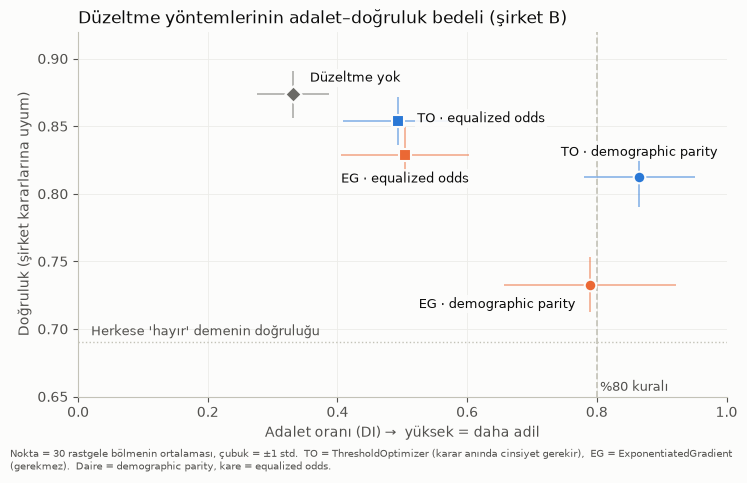

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

hepsi = pd.concat([sonuc30.drop(columns='seed', errors='ignore'),
                   sonuc_eg.drop(columns='seed', errors='ignore')])
ozet = hepsi.groupby('yöntem')[['doğruluk', 'DI']].agg(['mean', 'std'])

# (etiket, renk, işaret, etiket kayması, hizalama)
stil = {
    'Düzeltme yok':          ('Düzeltme yok',            '#6b6a66', 'D', (12, 12),  'left'),
    'demographic_parity':    ('TO · demographic parity', '#2a78d6', 'o', (0, 18),   'center'),
    'equalized_odds':        ('TO · equalized odds',     '#2a78d6', 's', (14, 2),   'left'),
    'EG_demographic_parity': ('EG · demographic parity', '#eb6834', 'o', (-10, -14), 'right'),
    'EG_equalized_odds':     ('EG · equalized odds',     '#eb6834', 's', (0, -17),  'center'),
}

fig, ax = plt.subplots(figsize=(7.5, 4.8))
fig.patch.set_facecolor('#fcfcfb'); ax.set_facecolor('#fcfcfb')

ax.axvline(0.8, color='#c3c2b7', lw=1.2, ls='--', zorder=1)
ax.text(0.805, 0.652, "%80 kuralı", color='#52514e', fontsize=9, va='bottom')
tabu = 1 - y.mean()
ax.axhline(tabu, color='#c3c2b7', lw=1, ls=':', zorder=1)
ax.text(0.02, tabu + 0.003, "Herkese 'hayır' demenin doğruluğu", color='#52514e', fontsize=9, va='bottom')

for ad, (etiket, renk, isaret, kayma, ha) in stil.items():
    dx, sx = ozet.loc[ad, ('DI', 'mean')], ozet.loc[ad, ('DI', 'std')]
    dy, sy = ozet.loc[ad, ('doğruluk', 'mean')], ozet.loc[ad, ('doğruluk', 'std')]
    ax.errorbar(dx, dy, xerr=sx, yerr=sy, fmt='none', ecolor=renk, elinewidth=1.2, alpha=0.55, capsize=0, zorder=2)
    ax.scatter(dx, dy, s=70, marker=isaret, color=renk, edgecolor='#fcfcfb', linewidth=1.5, zorder=3)
    ax.annotate(etiket, (dx, dy), textcoords='offset points', xytext=kayma,
                ha=ha, va='center', fontsize=9.5, color='#0b0b0b', zorder=4,
                bbox=dict(fc='#fcfcfb', ec='none', pad=1.5, alpha=0.9))

ax.set_xlim(0, 1.0); ax.set_ylim(0.65, 0.92)
ax.set_xlabel("Adalet oranı (DI) →  yüksek = daha adil", color='#52514e', fontsize=10)
ax.set_ylabel("Doğruluk (şirket kararlarına uyum)", color='#52514e', fontsize=10)
ax.set_title("Düzeltme yöntemlerinin adalet–doğruluk bedeli (şirket B)", loc='left', fontsize=12, color='#0b0b0b')
for s in ['top', 'right']: ax.spines[s].set_visible(False)
for s in ['left', 'bottom']: ax.spines[s].set_color('#c3c2b7')
ax.tick_params(colors='#52514e')
ax.grid(color='#ececE8', lw=0.6); ax.set_axisbelow(True)
fig.text(0.01, 0.01, "Nokta = 30 rastgele bölmenin ortalaması, çubuk = ±1 std.  TO = ThresholdOptimizer (karar anında cinsiyet gerekir),  EG = ExponentiatedGradient (gerekmez).  Daire = demographic parity, kare = equalized odds.",
         fontsize=7.5, color='#52514e', wrap=True)
fig.tight_layout(rect=(0, 0.04, 1, 1))
fig.savefig("adalet_dogruluk_bedeli.png", dpi=200)
plt.show()

In [7]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from fairlearn.metrics import (MetricFrame, selection_rate,
                               demographic_parity_ratio, equalized_odds_difference)
from fairlearn.postprocessing import ThresholdOptimizer
from fairlearn.reductions import ExponentiatedGradient, DemographicParity, EqualizedOdds


def veri_hazirla(df, sirket):
    d = df[(df['company'] == sirket) & (df['gender'].isin(['female', 'male']))].copy()
    cols = [c for c in df.columns if c.startswith('ind-')]
    X = pd.get_dummies(d[cols], columns=['ind-degree'], drop_first=True).astype(float)
    return X, d['decision'], d['gender']


def olc(y_true, y_pred, A_t):
    y_pred = np.asarray(y_pred)
    sr = MetricFrame(metrics=selection_rate, y_true=y_true, y_pred=y_pred,
                     sensitive_features=A_t).by_group
    return {
        'doğruluk': accuracy_score(y_true, y_pred),
        'DI': demographic_parity_ratio(y_true, y_pred, sensitive_features=A_t),
        'EO_farkı': equalized_odds_difference(y_true, y_pred, sensitive_features=A_t),
        'kadın_oran': sr['female'],
        'erkek_oran': sr['male'],
    }


def denetle(df, sirket, seeds=range(30), eg=True):
    X, y, A = veri_hazirla(df, sirket)
    strat = A.astype(str) + "_" + y.astype(str)
    kayit = []
    for seed in seeds:
        Xtr, Xte, ytr, yte, Atr, Ate = train_test_split(
            X, y, A, test_size=0.3, random_state=seed, stratify=strat)
        m = LogisticRegression(max_iter=1000).fit(Xtr, ytr)
        kayit.append({'şirket': sirket, 'seed': seed, 'yöntem': 'Düzeltme yok',
                      **olc(yte, m.predict(Xte), Ate)})
        for kisit in ['demographic_parity', 'equalized_odds']:
            to = ThresholdOptimizer(estimator=m, constraints=kisit,
                                    objective='accuracy_score', prefit=True,
                                    predict_method='predict_proba')
            to.fit(Xtr, ytr, sensitive_features=Atr)
            p = to.predict(Xte, sensitive_features=Ate, random_state=seed)
            kayit.append({'şirket': sirket, 'seed': seed, 'yöntem': 'TO_' + kisit,
                          **olc(yte, p, Ate)})
        if eg:
            for ad, kisit in [('EG_demographic_parity', DemographicParity()),
                              ('EG_equalized_odds', EqualizedOdds())]:
                e = ExponentiatedGradient(LogisticRegression(max_iter=1000), constraints=kisit)
                e.fit(Xtr, ytr, sensitive_features=Atr)
                kayit.append({'şirket': sirket, 'seed': seed, 'yöntem': ad,
                              **olc(yte, e.predict(Xte, random_state=seed), Ate)})
    return pd.DataFrame(kayit)


# kontrol: B'de eski sonuçları yeniden üretiyor mu?
df = pd.read_csv("recruitmentdataset-2022-1.3.csv")
sonuc_B = denetle(df, 'B', eg=False)
print(sonuc_B.groupby('yöntem')[['doğruluk', 'DI', 'EO_farkı']].mean().round(3))

                       doğruluk     DI  EO_farkı
yöntem                                          
Düzeltme yok              0.874  0.332     0.160
TO_demographic_parity     0.812  0.866     0.427
TO_equalized_odds         0.854  0.493     0.094


In [8]:
import time
t0 = time.time()
parcalar = []
for s in ['A', 'B', 'C', 'D']:
    parcalar.append(denetle(df, s))
    print(s, "bitti,", round(time.time() - t0), "sn")

sonuc_tum = pd.concat(parcalar, ignore_index=True)
sonuc_tum.to_csv("sonuc_tum.csv", index=False)

pd.set_option('display.width', 200)
kol = ['doğruluk', 'DI', 'EO_farkı', 'kadın_oran', 'erkek_oran']
print(sonuc_tum.groupby(['şirket', 'yöntem'])[kol].mean().round(3))

print()
for s in ['A', 'B', 'C', 'D']:
    _, y_s, _ = veri_hazirla(df, s)
    print(s, "herkese 'hayır' doğruluğu:", round(1 - y_s.mean(), 3))

A bitti, 19 sn
B bitti, 36 sn
C bitti, 54 sn
D bitti, 74 sn
                              doğruluk     DI  EO_farkı  kadın_oran  erkek_oran
şirket yöntem                                                                  
A      Düzeltme yok              0.729  0.771     0.117       0.346       0.450
       EG_demographic_parity     0.710  0.892     0.094       0.402       0.429
       EG_equalized_odds         0.707  0.856     0.097       0.374       0.427
       TO_demographic_parity     0.729  0.899     0.087       0.413       0.419
       TO_equalized_odds         0.720  0.887     0.095       0.424       0.461
B      Düzeltme yok              0.874  0.332     0.160       0.152       0.460
       EG_demographic_parity     0.733  0.789     0.146       0.161       0.187
       EG_equalized_odds         0.829  0.504     0.118       0.208       0.414
       TO_demographic_parity     0.812  0.866     0.427       0.245       0.246
       TO_equalized_odds         0.854  0.493     0.094     

In [9]:
# 1) D şirketi, kesilen satırlar
kol = ['doğruluk', 'DI', 'EO_farkı', 'kadın_oran', 'erkek_oran']
print(sonuc_tum[sonuc_tum['şirket'] == 'D'].groupby('yöntem')[kol].mean().round(3))

# 2) etiket DI'sı ile model DI'sı, aynı test bölmelerinde
etiket = []
for s in ['A', 'B', 'C', 'D']:
    X_s, y_s, A_s = veri_hazirla(df, s)
    strat_s = A_s.astype(str) + "_" + y_s.astype(str)
    for seed in range(30):
        _, _, _, yte, _, Ate = train_test_split(
            X_s, y_s, A_s, test_size=0.3, random_state=seed, stratify=strat_s)
        etiket.append({'şirket': s, 'seed': seed,
                       'DI_etiket': demographic_parity_ratio(yte, yte, sensitive_features=Ate)})
etiket = pd.DataFrame(etiket)

temel = (sonuc_tum[sonuc_tum['yöntem'] == 'Düzeltme yok'][['şirket', 'seed', 'DI']]
         .rename(columns={'DI': 'DI_model'}))
kar = etiket.merge(temel, on=['şirket', 'seed'])
print()
print(kar.groupby('şirket')[['DI_etiket', 'DI_model']].agg(['mean', 'std']).round(3))

                       doğruluk     DI  EO_farkı  kadın_oran  erkek_oran
yöntem                                                                  
Düzeltme yok              0.874  0.590     0.089       0.333       0.195
EG_demographic_parity     0.849  0.801     0.088       0.248       0.204
EG_equalized_odds         0.849  0.694     0.075       0.313       0.216
TO_demographic_parity     0.863  0.884     0.218       0.265       0.258
TO_equalized_odds         0.860  0.739     0.089       0.363       0.267

       DI_etiket      DI_model       
            mean  std     mean    std
şirket                               
A          0.850  0.0    0.771  0.093
B          0.309  0.0    0.332  0.055
C          0.845  0.0    0.657  0.141
D          0.632  0.0    0.590  0.074


In [10]:
def cevir(df, sirket, seeds=range(30)):
    X, y, A = veri_hazirla(df, sirket)
    Xg = X.copy()
    Xg['male'] = (A == 'male').astype(float)
    strat = A.astype(str) + "_" + y.astype(str)
    kayit = []
    for seed in seeds:
        Xtr, Xte, ytr, yte = train_test_split(
            Xg, y, test_size=0.3, random_state=seed, stratify=strat)
        m = LogisticRegression(max_iter=1000).fit(Xtr, ytr)
        p0 = m.predict_proba(Xte)[:, 1]
        Xc = Xte.copy()
        Xc['male'] = 1 - Xc['male']
        p1 = m.predict_proba(Xc)[:, 1]
        kadin = (Xte['male'] == 0).values
        kayit.append({
            'şirket': sirket, 'seed': seed,
            'kadın→erkek': (p1[kadin] - p0[kadin]).mean(),
            'erkek→kadın': (p1[~kadin] - p0[~kadin]).mean(),
            'OR_erkek/kadın': np.exp(m.coef_[0][list(Xg.columns).index('male')]),
        })
    return pd.DataFrame(kayit)

cevir_tum = pd.concat([cevir(df, s) for s in ['A', 'B', 'C', 'D']], ignore_index=True)
cevir_tum.to_csv("cevir_tum.csv", index=False)
print(cevir_tum.groupby('şirket')[['kadın→erkek', 'erkek→kadın', 'OR_erkek/kadın']]
      .agg(['mean', 'std']).round(3))

       kadın→erkek        erkek→kadın        OR_erkek/kadın       
              mean    std        mean    std           mean    std
şirket                                                            
A           -0.016  0.009       0.017  0.009          0.907  0.048
B            0.044  0.007      -0.073  0.013          1.949  0.189
C           -0.019  0.008       0.020  0.008          0.857  0.059
D           -0.007  0.010       0.006  0.008          0.933  0.101


In [11]:
for s in ['B', 'D']:
    d = df[(df['company'] == s) & (df['gender'].isin(['female', 'male']))]
    t = d.groupby('sport').agg(
        n=('decision', 'size'),
        erkek_payı=('gender', lambda g: (g == 'male').mean()),
        işe_alım=('decision', 'mean'),
    ).round(3)
    print(f"Şirket {s}")
    print(t.sort_values('işe_alım'))
    print()

Şirket B
            n  erkek_payı  işe_alım
sport                              
Chess      91       0.099     0.022
Golf       82       0.561     0.049
Running    76       0.250     0.066
Cricket    79       0.544     0.177
Swimming  157       0.344     0.204
Football  223       0.695     0.457
Tennis     97       0.639     0.515
Rugby     176       0.807     0.540

Şirket D
            n  erkek_payı  işe_alım
sport                              
Rugby     172       0.791     0.140
Football  209       0.708     0.225
Tennis     95       0.474     0.242
Cricket    85       0.647     0.318
Golf       78       0.615     0.333
Swimming  177       0.418     0.333
Running    71       0.254     0.394
Chess      88       0.091     0.398



In [12]:
def X_kur(d, set_adi):
    ind = [c for c in d.columns if c.startswith('ind-')]
    kolonlar = {'ind-*': ind,
                'sport': ['sport'],
                'ind-* + sport': ind + ['sport'],
                'ind-* + sport + yaş + uyruk': ind + ['sport', 'age', 'nationality']}[set_adi]
    kat = [c for c in kolonlar if c in ('ind-degree', 'sport', 'nationality')]
    return pd.get_dummies(d[kolonlar], columns=kat, drop_first=True).astype(float)

sonuc_abl = []
for s in ['B', 'D']:
    d = df[(df['company'] == s) & (df['gender'].isin(['female', 'male']))]
    y, A = d['decision'], d['gender']
    strat = A.astype(str) + "_" + y.astype(str)
    for ad in ['ind-*', 'sport', 'ind-* + sport', 'ind-* + sport + yaş + uyruk']:
        X = X_kur(d, ad)
        for seed in range(30):
            Xtr, Xte, ytr, yte, Atr, Ate = train_test_split(
                X, y, A, test_size=0.3, random_state=seed, stratify=strat)
            p = LogisticRegression(max_iter=1000).fit(Xtr, ytr).predict(Xte)
            sonuc_abl.append({'şirket': s, 'özellikler': ad, **olc(yte, p, Ate)})

print(pd.DataFrame(sonuc_abl).groupby(['şirket', 'özellikler'])[
    ['doğruluk', 'DI', 'kadın_oran', 'erkek_oran']].mean().round(3))

for s in ['B', 'D']:
    d = df[(df['company'] == s) & (df['gender'].isin(['female', 'male']))].copy()
    cols = [c for c in df.columns if c.startswith('ind-') and c != 'ind-degree']
    t = d.groupby('gender')[cols].mean().T
    t['fark(e-k)'] = t['male'] - t['female']
    t['karar_korelasyon'] = [d[c].astype(float).corr(d['decision'].astype(float)) for c in cols]
    print(f"\nŞirket {s}")
    print(t.round(3))
    print(pd.crosstab(d['gender'], d['ind-degree'], normalize='index').round(3))

                                    doğruluk     DI  kadın_oran  erkek_oran
şirket özellikler                                                          
B      ind-*                           0.874  0.332       0.152       0.460
       ind-* + sport                   0.876  0.313       0.144       0.461
       ind-* + sport + yaş + uyruk     0.877  0.317       0.145       0.459
       sport                           0.691  0.435       0.097       0.237
D      ind-*                           0.874  0.590       0.333       0.195
       ind-* + sport                   0.872  0.596       0.330       0.195
       ind-* + sport + yaş + uyruk     0.872  0.625       0.324       0.201
       sport                           0.724    NaN       0.000       0.000

Şirket B
gender                 female    male  fark(e-k)  karar_korelasyon
ind-university_grade   64.153  60.774     -3.379            -0.154
ind-debateclub          0.126   0.349      0.223             0.609
ind-programming_exp     0.439

In [13]:
from sklearn.metrics import roc_auc_score

# 1) D şirketinin ind-* ortalamaları
d = df[(df['company'] == 'D') & (df['gender'].isin(['female', 'male']))].copy()
cols = [c for c in df.columns if c.startswith('ind-') and c != 'ind-degree']
t = d.groupby('gender')[cols].mean().T
t['fark(e-k)'] = t['male'] - t['female']
t['karar_korelasyon'] = [d[c].astype(float).corr(d['decision'].astype(float)) for c in cols]
print("Şirket D")
print(t.round(3))

# 2) eşik gerektirmeyen ölçüm: AUC
satir = []
for s in ['B', 'D']:
    d = df[(df['company'] == s) & (df['gender'].isin(['female', 'male']))]
    y, A = d['decision'], d['gender']
    cins = (A == 'male').astype(int)
    strat = A.astype(str) + "_" + y.astype(str)
    for ad in ['sport', 'ind-*', 'ind-* + sport']:
        X = X_kur(d, ad)
        for seed in range(30):
            Xtr, Xte, ytr, yte, ctr, cte = train_test_split(
                X, y, cins, test_size=0.3, random_state=seed, stratify=strat)
            auc_karar = roc_auc_score(yte, LogisticRegression(max_iter=1000).fit(Xtr, ytr).predict_proba(Xte)[:, 1])
            auc_cins = roc_auc_score(cte, LogisticRegression(max_iter=1000).fit(Xtr, ctr).predict_proba(Xte)[:, 1])
            satir.append({'şirket': s, 'özellikler': ad, 'AUC_karar': auc_karar, 'AUC_cinsiyet': auc_cins})

print()
print(pd.DataFrame(satir).groupby(['şirket', 'özellikler'])[['AUC_karar', 'AUC_cinsiyet']].mean().round(3))

Şirket D
gender                 female    male  fark(e-k)  karar_korelasyon
ind-university_grade   64.280  61.060     -3.220             0.650
ind-debateclub          0.099   0.323      0.224            -0.164
ind-programming_exp     0.472   0.222     -0.250             0.412
ind-international_exp   0.192   0.246      0.054             0.008
ind-entrepeneur_exp     0.088   0.303      0.215            -0.126
ind-languages           1.025   1.573      0.548            -0.003
ind-exact_study         0.614   0.368     -0.246             0.482

                      AUC_karar  AUC_cinsiyet
şirket özellikler                            
B      ind-*              0.945         0.757
       ind-* + sport      0.950         0.787
       sport              0.746         0.739
D      ind-*              0.946         0.742
       ind-* + sport      0.944         0.776
       sport              0.592         0.732


In [14]:
rng = np.random.default_rng(0)
for s in ['A', 'B', 'C', 'D']:
    d = df[(df['company'] == s) & (df['gender'].isin(['female', 'male']))]
    y = d['decision'].values.astype(int)
    erkek = (d['gender'] == 'male').values
    di = []
    for _ in range(5000):
        idx = rng.integers(0, len(d), len(d))
        yb, eb = y[idx], erkek[idx]
        k, e = yb[~eb].mean(), yb[eb].mean()
        di.append(min(k, e) / max(k, e))
    di = np.array(di)
    nokta = min(y[~erkek].mean(), y[erkek].mean()) / max(y[~erkek].mean(), y[erkek].mean())
    print(f"{s}: DI={nokta:.3f}  %95 aralık=({np.percentile(di, 2.5):.3f}, {np.percentile(di, 97.5):.3f})"
          f"  DI<0.8 olan örnek payı={np.mean(di < 0.8):.2f}")

A: DI=0.845  %95 aralık=(0.725, 0.975)  DI<0.8 olan örnek payı=0.23
B: DI=0.307  %95 aralık=(0.233, 0.387)  DI<0.8 olan örnek payı=1.00
C: DI=0.846  %95 aralık=(0.678, 0.988)  DI<0.8 olan örnek payı=0.32
D: DI=0.641  %95 aralık=(0.522, 0.791)  DI<0.8 olan örnek payı=0.98


In [15]:
import pandas as pd
import denetim as dn

df = pd.read_csv("recruitmentdataset-2022-1.3.csv")
sonuc_B = dn.denetle(df, 'B', eg=False)
print(sonuc_B.groupby('yöntem')[['doğruluk', 'DI', 'EO_farkı']].mean().round(3))

                       doğruluk     DI  EO_farkı
yöntem                                          
Düzeltme yok              0.874  0.332     0.160
TO_demographic_parity     0.812  0.866     0.427
TO_equalized_odds         0.854  0.493     0.094


In [16]:
import numpy as np
from sklearn.linear_model import LogisticRegression

rng = np.random.default_rng(0)
for s in ['A', 'B', 'C', 'D']:
    X, y, A = dn.veri_hazirla(df, s)
    Xg = X.copy()
    Xg['male'] = (A == 'male').astype(float)
    kol = list(Xg.columns).index('male')

    def or_hesapla(Xb, yb):
        m = LogisticRegression(C=1e6, max_iter=5000).fit(Xb, yb)
        return np.exp(m.coef_[0][kol])

    nokta = or_hesapla(Xg, y)
    bs = []
    for _ in range(500):
        idx = rng.integers(0, len(Xg), len(Xg))
        bs.append(or_hesapla(Xg.iloc[idx], y.iloc[idx]))
    bs = np.array(bs)
    print(f"{s}: OR(erkek/kadın)={nokta:.2f}  %95 aralık=({np.percentile(bs, 2.5):.2f}, {np.percentile(bs, 97.5):.2f})"
          f"  1'i kapsıyor mu: {np.percentile(bs, 2.5) <= 1 <= np.percentile(bs, 97.5)}")

A: OR(erkek/kadın)=0.88  %95 aralık=(0.61, 1.19)  1'i kapsıyor mu: True
B: OR(erkek/kadın)=1.98  %95 aralık=(1.16, 3.45)  1'i kapsıyor mu: False
C: OR(erkek/kadın)=0.85  %95 aralık=(0.55, 1.27)  1'i kapsıyor mu: True
D: OR(erkek/kadın)=0.91  %95 aralık=(0.55, 1.53)  1'i kapsıyor mu: True


In [17]:
rng = np.random.default_rng(0)
bs_hepsi = {}
for s in ['A', 'B', 'C', 'D']:
    X, y, A = dn.veri_hazirla(df, s)
    Xg = X.copy()
    Xg['male'] = (A == 'male').astype(float)
    kol = list(Xg.columns).index('male')

    def or_hesapla(Xb, yb):
        m = LogisticRegression(C=1e6, max_iter=5000).fit(Xb, yb)
        return np.exp(m.coef_[0][kol])

    bs = []
    for _ in range(500):
        idx = rng.integers(0, len(Xg), len(Xg))
        bs.append(or_hesapla(Xg.iloc[idx], y.iloc[idx]))
    bs_hepsi[s] = np.log(np.array(bs))

for s in ['A', 'C', 'D']:
    fark = bs_hepsi['B'] - bs_hepsi[s]
    alt, ust = np.percentile(fark, 2.5), np.percentile(fark, 97.5)
    print(f"B - {s}: log-OR farkı={fark.mean():.2f}  %95 aralık=({alt:.2f}, {ust:.2f})  0'ı kapsıyor mu: {alt <= 0 <= ust}")

B - A: log-OR farkı=0.84  %95 aralık=(0.20, 1.45)  0'ı kapsıyor mu: False
B - C: log-OR farkı=0.84  %95 aralık=(0.15, 1.55)  0'ı kapsıyor mu: False
B - D: log-OR farkı=0.78  %95 aralık=(0.05, 1.50)  0'ı kapsıyor mu: False
